# Diabetes 130-US Hospitals

## 1. EDA & problem framing

### Downloading necessary libraries

We start by downloading the necessary libraries to better visualize the data

In [3]:
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

### Dataset loading

Load the data from the sklearn library (Diabetes data)

In [5]:
import pandas as pd

from sklearn.datasets import fetch_openml
# Option 3 -- Diabetes 130 Hospitals
diabetes = fetch_openml(data_id=4541, as_frame=True)
X, y = diabetes.data, diabetes.target

# 1.1 Problem Definition

#### Goal: Predict whether a patient will be readmitted to the hospital
#### The data comes from 130 US hospitals between 1999-2008; each row is one hospital stay of a patient with diabetes. The same patient could have several stays.


# 1.2 Target 

#### Readmitted has 3 labels, <30; >30 and NO.

In [6]:
y.value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

#### Check to see there no missing values in the target

In [7]:
y.isna().sum()

np.int64(0)

#### We convert it to binary values (1, 0) maning yes and no respectively.

In [8]:
y = y.map({'NO': 0, '<30': 1, '>30': 1})

#### Check to make sure it works!

In [9]:
y.value_counts()

readmitted
0    54864
1    46902
Name: count, dtype: int64

# 1.3 Visualize the data

In [10]:
df = pd.DataFrame(X, columns=diabetes.feature_names)

In [11]:
df.shape

(101766, 49)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 49 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   encounter_id              101766 non-null  int64   
 1   patient_nbr               101766 non-null  int64   
 2   race                      101766 non-null  category
 3   gender                    101766 non-null  category
 4   age                       101766 non-null  category
 5   weight                    101766 non-null  category
 6   admission_type_id         101766 non-null  int64   
 7   discharge_disposition_id  101766 non-null  int64   
 8   admission_source_id       101766 non-null  int64   
 9   time_in_hospital          101766 non-null  int64   
 10  payer_code                101766 non-null  category
 11  medical_specialty         101766 non-null  category
 12  num_lab_procedures        101766 non-null  int64   
 13  num_procedures            101

### We see the data inside each row and as we can see we have some data that has question marks, so we need to change them to NaaNs to have a better view

In [13]:
df.head(10)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,examide,citoglipton,insulin,glyburide.metformin,glipizide.metformin,glimepiride.pioglitazone,metformin.rosiglitazone,metformin.pioglitazone,change,diabetesMed
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,No
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,No,Up,No,No,No,No,No,Ch,Yes
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,No,Yes
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,No,Up,No,No,No,No,No,Ch,Yes
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,No,Steady,No,No,No,No,No,Ch,Yes
5,35754,82637451,Caucasian,Male,[50-60),?,2,1,2,3,...,No,No,Steady,No,No,No,No,No,No,Yes
6,55842,84259809,Caucasian,Male,[60-70),?,3,1,2,4,...,No,No,Steady,No,No,No,No,No,Ch,Yes
7,63768,114882984,Caucasian,Male,[70-80),?,1,1,7,5,...,No,No,No,No,No,No,No,No,No,Yes
8,12522,48330783,Caucasian,Female,[80-90),?,2,1,4,13,...,No,No,Steady,No,No,No,No,No,Ch,Yes
9,15738,63555939,Caucasian,Female,[90-100),?,3,3,4,12,...,No,No,Steady,No,No,No,No,No,Ch,Yes


#### We create a list called cols_count that includes the countable features in our dataset. Below we can see the descriptive statistics of said features.

##### Below we can see the stays in the hospitals range between 1 to 14 days.
##### We can see that for each patient, there needs to be AT LEAST 1 lab procedure.

In [14]:
cols_count = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
df[cols_count].describe()

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


# 1.4 Cleaning the Data

##### We do a missingno matrix and immediately see that there are no missing values, which is strange. After reviewing the data, we can see that there are ?'s in these columns (weight, medical specialty, payer_code and race). 
##### We also saw that there is a 'None' value in the A1Cresult and max_glu_serum which means no test was performed.
##### Moreover, the gender column has 3 stays which are were recorded as Unknown/Invalid.
##### We also check for duplicated in our data and see that there are none.

<Axes: >

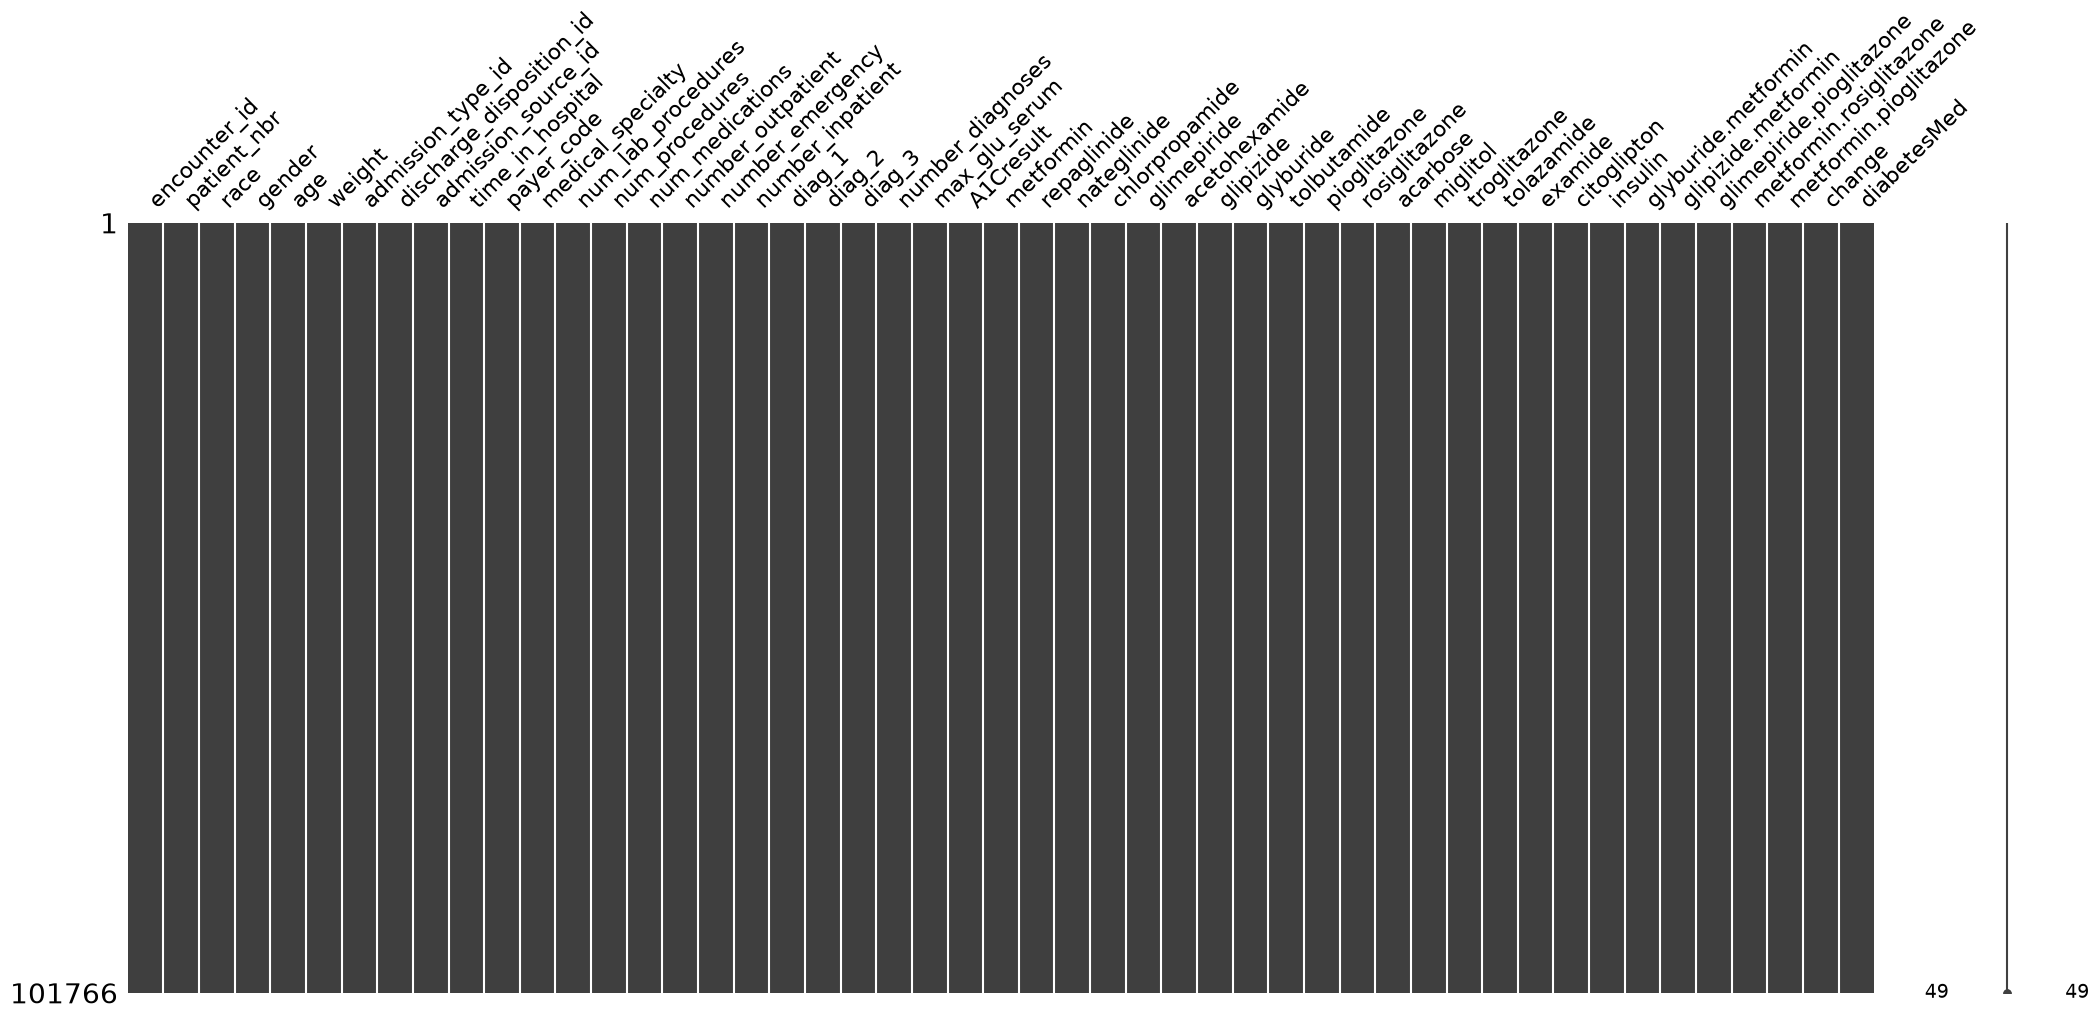

In [12]:
msno.matrix(df)

In [13]:
df.duplicated().sum()

np.int64(0)

##### Now we replace all the missing values with NaaN.

In [15]:
df = df.replace('?', np.nan)
df = df.replace('None', np.nan)
df = df.replace('Unknown/Invalid', np.nan)
df.isna().sum()

/var/folders/6z/9jpq2f2d3hz2c3bgp4wmwwjr0000gn/T/ipykernel_95712/454572088.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  df = df.replace('?', np.nan)
/var/folders/6z/9jpq2f2d3hz2c3bgp4wmwwjr0000gn/T/ipykernel_95712/454572088.py:2: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  df = df.replace('None', np.nan)
/var/folders/6z/9jpq2f2d3hz2c3bgp4wmwwjr0000gn/T/ipykernel_95712/454572088.py:3: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that prese

encounter_id                    0
patient_nbr                     0
race                         2273
gender                          3
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

##### Now that we established that we have a lot of missing values, we will delete the top 5 columns because even if we fill with the mean, median or mode, the analysis will be flawed.

In [16]:
missing_percentage = df.isna().sum() / len(df) * 100
missing_percentage[missing_percentage > 0].sort_values(ascending=False).round(4)

weight               96.8585
max_glu_serum        94.7468
A1Cresult            83.2773
medical_specialty    49.0822
payer_code           39.5574
race                  2.2336
diag_3                1.3983
diag_2                0.3518
diag_1                0.0206
gender                0.0029
dtype: float64

In [17]:
df = df.drop(columns=['weight', 'max_glu_serum', 'A1Cresult', 'medical_specialty','payer_code'])

##### Now, we replace diagnostic missing values with "Unknown".

In [18]:
for col in ["diag_1", "diag_2", "diag_3"]:
    df[col] = df[col].astype("string").fillna("Unknown")

<Axes: >

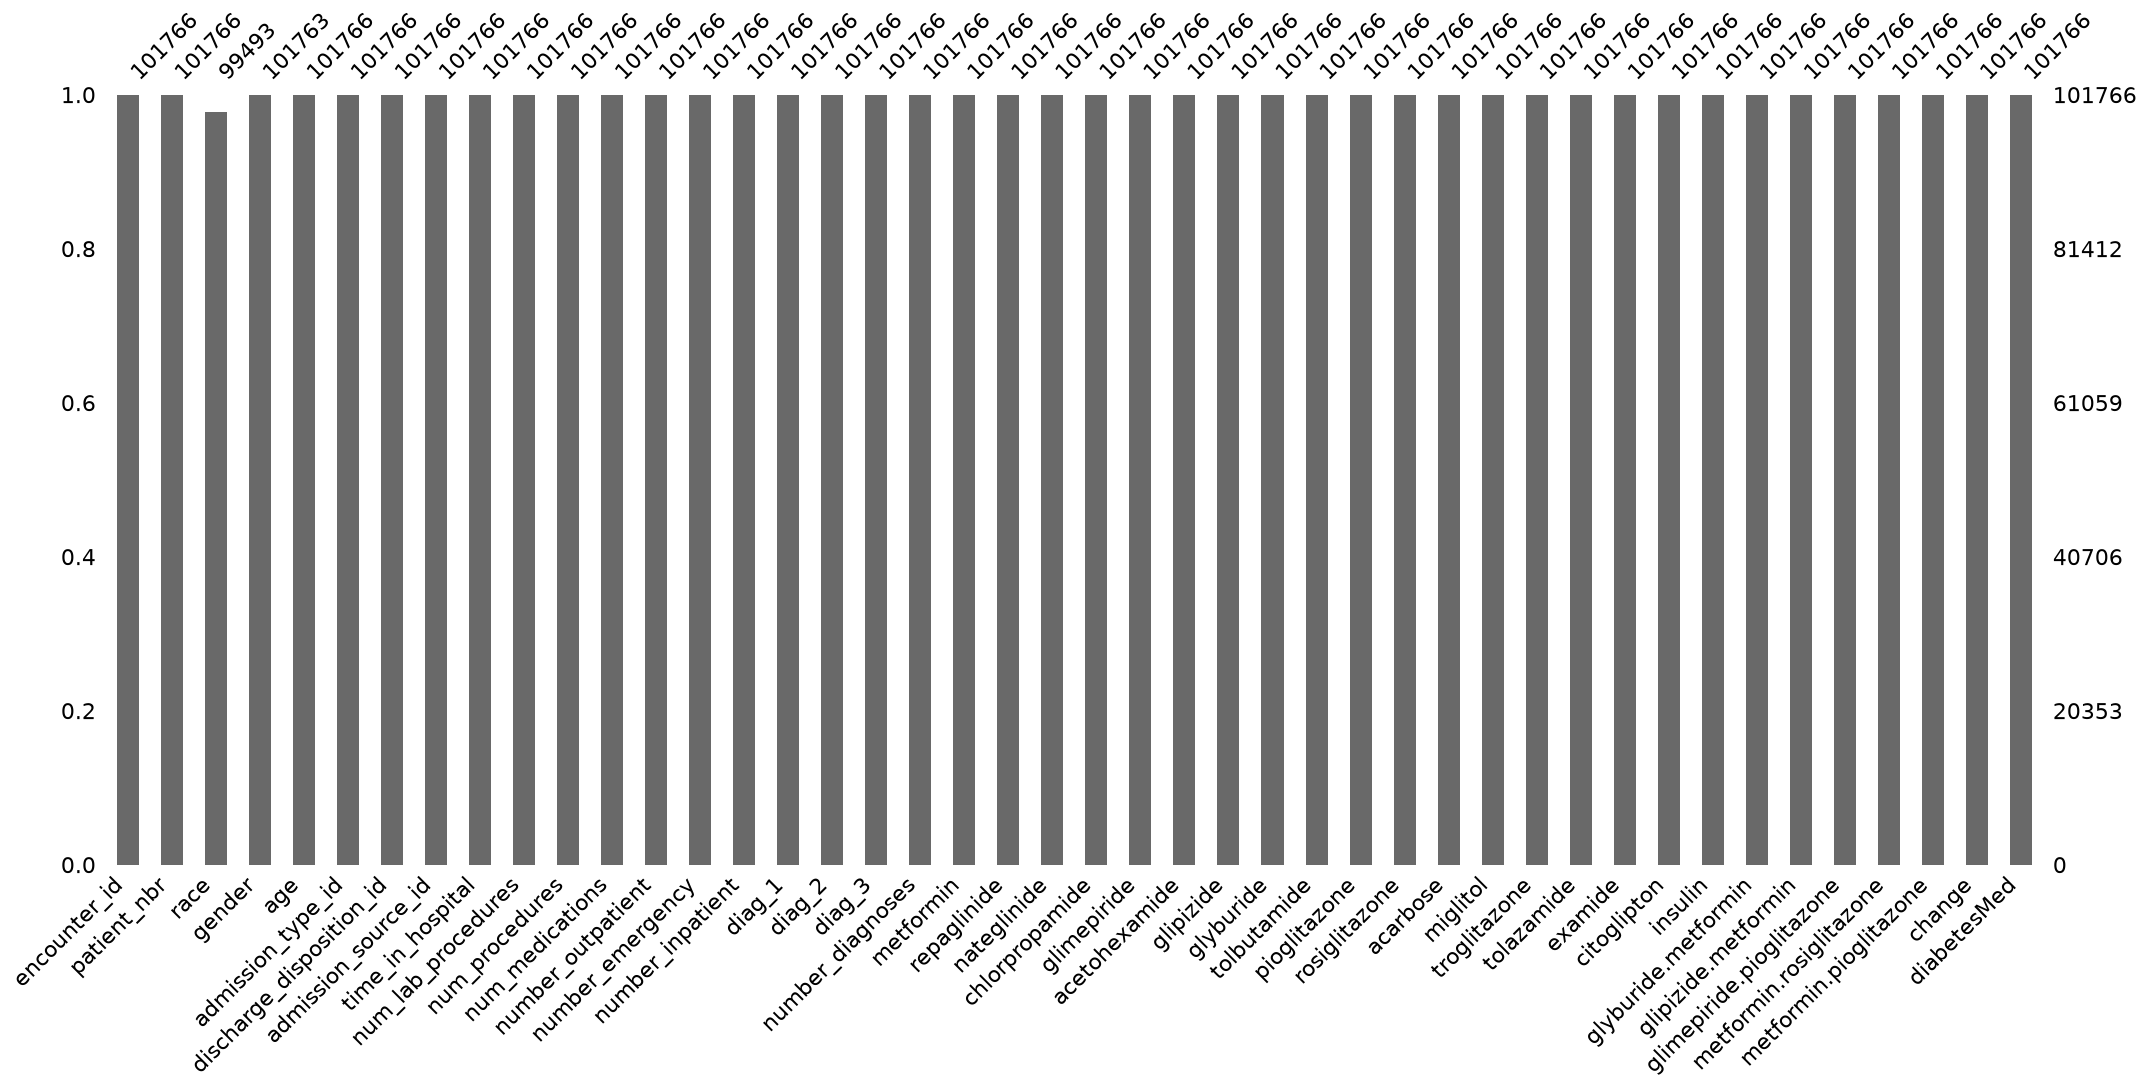

In [18]:
msno.bar(df)

### We run a df.describe on the diagnoses and see which diagnosis is most repititive. 
#### 1. Based on the information below, the main diagnosis is 428 which refers to heart failure :(
#### 2. Then, the second most common diagnosis is 276 which is disorder of fluid :(
#### 3. Finally, the third most common diagnosis is 250 which is Diabetes Mellitus :(

In [19]:
df[["diag_1", "diag_2", "diag_3"]].mode()

,diag_1,diag_2,diag_3
0,428,276,250


# 1.5 Variables Distributions 

##### Visualize the binary target distribution in percentages.

In [20]:
y.value_counts(normalize=True) * 100

readmitted
0    53.911916
1    46.088084
Name: proportion, dtype: float64

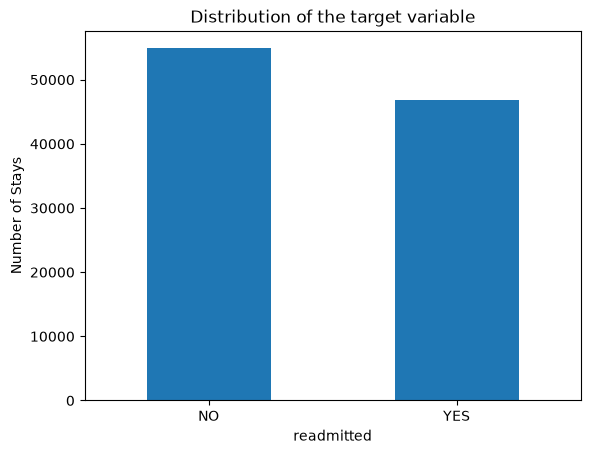

In [21]:
y.value_counts().sort_index().plot.bar()
plt.title("Distribution of the target variable")
plt.xticks([0, 1], ['NO', 'YES'], rotation=0)
plt.ylabel("Number of Stays")
plt.show()

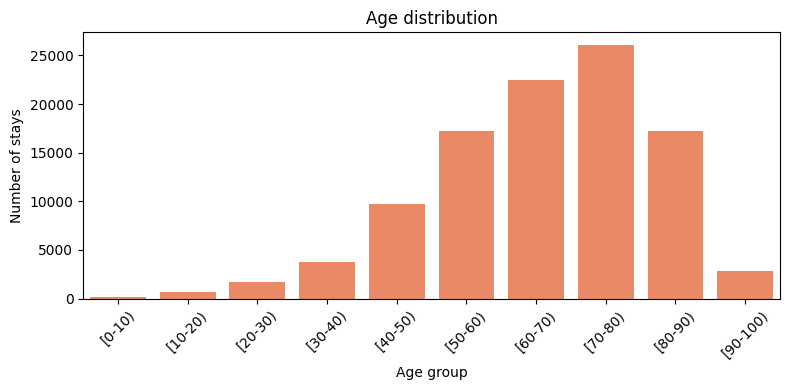

In [20]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="age", order=sorted(df["age"].unique()), color="coral")
plt.title("Age distribution")
plt.xlabel("Age group")
plt.ylabel("Number of stays")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

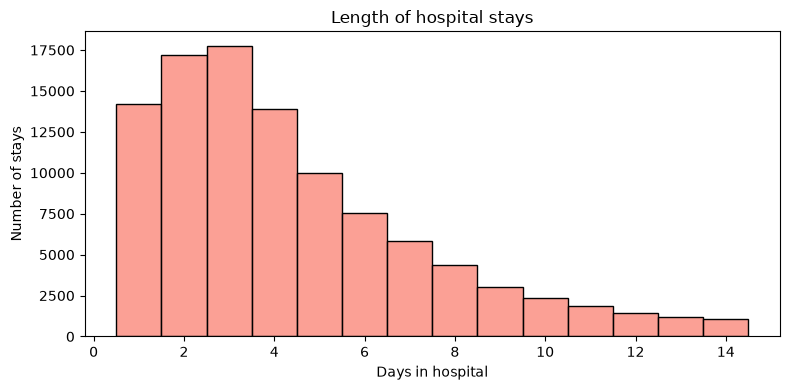

In [23]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="time_in_hospital", discrete=True, color="salmon")
plt.title("Length of hospital stays")
plt.xlabel("Days in hospital")
plt.ylabel("Number of stays")
plt.tight_layout()
plt.show()


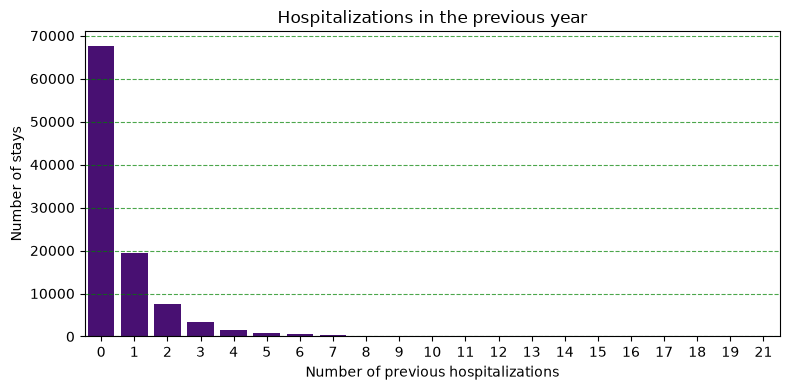

In [24]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="number_inpatient", color="indigo")
plt.grid(axis='y', linestyle='--', alpha=0.7, color='green')
plt.title("Hospitalizations in the previous year")
plt.xlabel("Number of previous hospitalizations")
plt.ylabel("Number of stays")
plt.tight_layout()
plt.show()

##### Now we look into the patients that have been admitted multiple times and patients that have been admitted only once.
##### To break down the maths, we take the number of patients with several stays and subtract it from the unique patients and then add the total stays for patients with several days, which gives us the total number of admissions (101,766).

In [25]:
stays_per_patient = df["patient_nbr"].value_counts()

print("Unique patients:", stays_per_patient.size)
print("Patients with several stays:", (stays_per_patient > 1).sum())
print("Total stays for patients with several stays:", stays_per_patient[stays_per_patient > 1].sum())

Unique patients: 71518
Patients with several stays: 16773
Total stays for patients with several stays: 47021


# 1.6 Splitting the data

##### We split train and test per patient; we import GroupKFold which allows us to split the data whitout separating groups (patient with multiple admissions).
##### We set nsplits = 5 to have an 80/20 split.

In [21]:
from sklearn.model_selection import GroupKFold

split = GroupKFold(n_splits=5, shuffle=True, random_state=42)

train_set, test_set = next(
    split.split(df, y, groups=df["patient_nbr"])
)

X_train = df.iloc[train_set].copy()
X_test = df.iloc[test_set].copy()

y_train = y.iloc[train_set].copy()
y_test = y.iloc[test_set].copy()

##### We verify the sepratation and since the resulet is set(), we know that both sets don't have a common patient.

In [22]:
set(X_train["patient_nbr"]) & set(X_test["patient_nbr"])

set()

##### Next, we store the patient_nbr in groups_train for cross validation then delete them because they aren't medical characteristics.

In [23]:
groups_train = X_train["patient_nbr"]

X_train = X_train.drop(columns=["encounter_id", "patient_nbr"])
X_test = X_test.drop(columns=["encounter_id", "patient_nbr"])

### EDA conclusion

Our goal is to predict whether a hospital stay will be followed by a recorded readmission, regardless of the delay. We plan to make predictions at discharge.

The target is binary: 1 for a recorded readmission (⁠ <30 ⁠ or ⁠ >30 ⁠) and 0 for no recorded readmission (⁠ NO ⁠). About 46% of stays belong to class 1, so the classes are relatively balanced.

The dataset contains 101,766 stays from 71,518 patients. Among these patients, 16,773 have multiple stays. We will therefore split the data by patient to prevent overlap between training and test sets.

Unknown diagnosis codes are represented by an "Unknown" category. Diagnosis codes and other category codes will be treated as categorical variables.

We split the data before fitting any imputation or encoding. Patient and encounter identifiers are excluded from the model's predictors.

# 2. Feature Engineering

##### We do a for loop over each line so we could identify the total number of visits per stay throughout the year before hospitalisation. Then, we devide the number of lab procedures during the encounter by the time spent in hospital to figure out the number of lab procedures per day.

In [24]:
for data in [X_train, X_test]:
    data["previous_visits"] = (
        data["number_outpatient"]
        + data["number_emergency"]
        + data["number_inpatient"]
    )

    data["lab_procedures_per_day"] = (
        data["num_lab_procedures"] / data["time_in_hospital"]
    )

In [30]:
X_train[["previous_visits", "lab_procedures_per_day"]].sample(10)

,previous_visits,lab_procedures_per_day
13442,0,47.000000
90312,9,13.400000
1334,0,12.000000
46862,3,11.000000
80734,0,59.000000
85166,0,0.333333
77948,1,22.000000
39223,0,0.750000
92279,0,28.500000
74623,0,15.333333


##### Separating the numerical and categorical columns.

In [28]:
numeric_columns = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
    "previous_visits",
    "lab_procedures_per_day"
]

categorical_columns = X_train.columns.drop(numeric_columns).tolist()

In [29]:
print("Numerical:", numeric_columns)
print("Categorical:", categorical_columns)

Numerical: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'previous_visits', 'lab_procedures_per_day']
Categorical: ['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'diag_1', 'diag_2', 'diag_3', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide.metformin', 'glipizide.metformin', 'glimepiride.pioglitazone', 'metformin.rosiglitazone', 'metformin.pioglitazone', 'change', 'diabetesMed']


##### We set up the pipelines, where the numerical pipeline we set up the imputer and standard scaler, then for the categorical pipeline we set up the imputer and encoder of choice (OneHotEncoder). We chose OneHotEncoder because we wanted to transform the categories to numbers without creating an order between them and avoid data leakage.

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

##### We add a ColumnTransformer which is a preprocessor which applies the preprocess into the pipeline.

In [31]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# 3. Class Imbalance Handling

##### The training classes are more or less balanced. We should keep the original distribution without oversampling or undersampling.
##### We will compare the models by computing the accuracy, precision, recall, F1-score and ROC-AUC.
##### We will also compare class weighting with no weighting during the model selection and rather during the model training, while also using cross-validation on the development set.

In [32]:
y_train.value_counts(normalize=True) * 100

readmitted
0    53.729185
1    46.270815
Name: proportion, dtype: float64

## 4. Modelling progression

##### Now it's time to set up the 4 type of models we want to use, we decided to use Logistic Regression, Random Forest, CatBoost and LightGBM.
The choice behind choosing these 4 types of models is because they use different approaches to learn from the data. 

Logistic Regression has a simple baseline to predict readmission and understand correlation between features.

Random Forest can capture the nonlinear relationships.

LightGBM builds trees to improve which allows us to test whether boosting improves the predictions.

CatBoost handles categorical features directly, making it suitable for our dataset with many categorical variables, including diagnosis codes.

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


logistic = LogisticRegression(max_iter=1000, random_state=42)
forest = RandomForestClassifier(random_state=42)
lightgbm = LGBMClassifier(random_state=42)
catboost = CatBoostClassifier(iterations=300, cat_features=tuple(categorical_columns), random_seed=42, verbose=False, allow_writing_files=False)


In [34]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", logistic)
])

forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", forest)
])

lightgbm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", lightgbm)
])

catboost_preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline["imputer"], numeric_columns),
    ("categorical", categorical_pipeline["imputer"], categorical_columns)
], verbose_feature_names_out=False).set_output(transform="pandas")

catboost_pipeline = Pipeline([
    ("preprocessor", catboost_preprocessor),
    ("model", catboost)
])

##### This sets up five-fold cross-validation, keeping each patient’s stays together and defines the same five evaluation metrics for all three models.

In [35]:
from sklearn.model_selection import cross_validate, GroupKFold

cv = GroupKFold(n_splits=5, shuffle=True, random_state=42)

metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

In [ ]:
logistic_scores = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=metrics,
    error_score="raise"
)

logistic_results = pd.DataFrame(logistic_scores)
logistic_results.mean()

fit_time          2.337041
score_time        0.150764
test_accuracy     0.637454
test_precision    0.627333
test_recall       0.533207
test_f1           0.576422
test_roc_auc      0.690899
dtype: float64

In [ ]:
forest_scores = cross_validate(
    forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=metrics,
    error_score="raise"
)

forest_results = pd.DataFrame(forest_scores)
forest_results.mean()

fit_time          63.441776
score_time         1.425701
test_accuracy      0.639992
test_precision     0.633173
test_recall        0.527594
test_f1            0.575572
test_roc_auc       0.691691
dtype: float64

In [ ]:
lightgbm_scores = cross_validate(
    lightgbm_pipeline,
    X_train,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=metrics,
    error_score="raise"
)

lightgbm_results = pd.DataFrame(lightgbm_scores)
lightgbm_results.mean()

[LightGBM] [Info] Number of positive: 30105, number of negative: 35041
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006214 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2257
[LightGBM] [Info] Number of data points in the train set: 65146, number of used features: 845
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.462116 -> initscore=-0.151828
[LightGBM] [Info] Start training from score -0.151828
[LightGBM] [Info] Number of positive: 30178, number of negative: 35135
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005630 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2229
[LightGBM] [Info] Number of data points in the train set: 65313, number of used features: 837
[LightGBM] [Info

fit_time          1.119632
score_time        0.216663
test_accuracy     0.645749
test_precision    0.633155
test_recall       0.557218
test_f1           0.592721
test_roc_auc      0.702293
dtype: float64

In [ ]:
catboost_scores = cross_validate(
    catboost_pipeline,
    X_train,
    y_train,
    cv=cv,
    groups=groups_train,
    scoring=metrics,
    error_score="raise"
)

catboost_results = pd.DataFrame(catboost_scores)
catboost_results.mean()

fit_time          17.137122
score_time         0.208137
test_accuracy      0.649357
test_precision     0.634958
test_recall        0.569801
test_f1            0.600490
test_roc_auc       0.707329
dtype: float64

In [36]:
comparison = pd.DataFrame({
    "Logistic Regression": logistic_results.filter(like="test_").mean(),
    "Random Forest": forest_results.filter(like="test_").mean(),
    "LightGBM": lightgbm_results.filter(like="test_").mean(),
    "CatBoost": catboost_results.filter(like="test_").mean()
}).T

comparison.round(3)

NameError: name 'logistic_results' is not defined

## 5. Pipeline

### Candidate pipelines

We retain LightGBM and CatBoost for hyperparameter tuning because performances are really similar, and we want to see both performances after tuning.
The final classifier will be selected after tuning.

The LightGBM and CatBoost pipelines reuse the preprocessing already defined in Section 2 and 4, so we do not redefine it here.

In [ ]:
lightgbm_candidate = Pipeline([
    ("preprocessor", preprocessor),
    ("model", lightgbm)
])

catboost_candidate = Pipeline([
    ("preprocessor", catboost_preprocessor),
    ("model", catboost)
])

## 6. Hyperparameter tuning

#### We prepare the tuning for LightGBM

In [ ]:
import optuna

def objective_lightgbm(trial):

    model = LGBMClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 500, step=100),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2),
        num_leaves=trial.suggest_int("num_leaves", 15, 127),
        min_child_samples=trial.suggest_int("min_child_samples", 20, 100, step=20),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
        random_state=42,
        verbosity=-1
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv,
        groups=groups_train,
        scoring=metrics,
        error_score="raise"
    )

    for name, values in scores.items():
        trial.set_user_attr(name, values.tolist())

    return scores["test_roc_auc"].mean()

In [ ]:
study_lightgbm = optuna.create_study(
    study_name="lightgbm_tuning",
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    storage="sqlite:///optuna_results.db",
    load_if_exists=True
)

study_lightgbm.optimize(objective_lightgbm, n_trials=50)

[I 2026-10-20 17:07:03,422] A new study created in RDB with name: lightgbm_tuning
[I 2026-10-20 17:07:22,078] Trial 0 finished with value: 0.6875752134170015 and parameters: {'n_estimators': 200, 'learning_rate': 0.19063571821788408, 'num_leaves': 97, 'min_child_samples': 60, 'class_weight': None}. Best is trial 0 with value: 0.6875752134170015.
[I 2026-10-20 17:07:30,985] Trial 1 finished with value: 0.6978189154923256 and parameters: {'n_estimators': 100, 'learning_rate': 0.1745734676972377, 'num_leaves': 82, 'min_child_samples': 80, 'class_weight': 'balanced'}. Best is trial 1 with value: 0.6978189154923256.
[I 2026-10-20 17:07:50,287] Trial 2 finished with value: 0.7021081827399358 and parameters: {'n_estimators': 500, 'learning_rate': 0.05034443102887247, 'num_leaves': 35, 'min_child_samples': 20, 'class_weight': 'balanced'}. Best is trial 2 with value: 0.7021081827399358.
[I 2026-10-20 17:08:14,760] Trial 3 finished with value: 0.6998221313015941 and parameters: {'n_estimators': 

In [ ]:
print("Best ROC-AUC:", study_lightgbm.best_value)
print("Best parameters:", study_lightgbm.best_params)

Best ROC-AUC: 0.7053308958423451
Best parameters: {'n_estimators': 400, 'learning_rate': 0.020617118634099374, 'num_leaves': 71, 'min_child_samples': 100, 'class_weight': None}


#### Now we also prepare tuning for Catboost, to see which one will be the most performant

In [ ]:
def objective_catboost(trial):

    model = CatBoostClassifier(
        iterations=trial.suggest_int("iterations", 100, 500, step=100),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2),
        depth=trial.suggest_int("depth", 4, 8),
        auto_class_weights=trial.suggest_categorical(
            "auto_class_weights", [None, "Balanced"]
        ),
        cat_features=tuple(categorical_columns),
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    )

    pipeline = Pipeline([
        ("preprocessor", catboost_preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv,
        groups=groups_train,
        scoring=metrics,
        error_score="raise"
    )

    for name, values in scores.items():
        trial.set_user_attr(name, values.tolist())

    return scores["test_roc_auc"].mean()

In [ ]:
study_catboost = optuna.create_study(
    study_name="catboost_tuning",
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    storage="sqlite:///optuna_results.db",
    load_if_exists=True
)

study_catboost.optimize(objective_catboost, n_trials=50)

[I 2026-10-20 17:30:23,996] A new study created in RDB with name: catboost_tuning
[I 2026-10-20 17:31:27,066] Trial 0 finished with value: 0.7054773595254411 and parameters: {'iterations': 200, 'learning_rate': 0.19063571821788408, 'depth': 7, 'auto_class_weights': None}. Best is trial 0 with value: 0.7054773595254411.
[I 2026-10-20 17:31:43,937] Trial 1 finished with value: 0.6934813228954043 and parameters: {'iterations': 100, 'learning_rate': 0.021035886311957897, 'depth': 8, 'auto_class_weights': 'Balanced'}. Best is trial 0 with value: 0.7054773595254411.
[I 2026-10-20 17:32:02,706] Trial 2 finished with value: 0.7031064652053667 and parameters: {'iterations': 100, 'learning_rate': 0.19428287191077892, 'depth': 8, 'auto_class_weights': None}. Best is trial 0 with value: 0.7054773595254411.
[I 2026-10-20 17:32:17,461] Trial 3 finished with value: 0.7003061185972312 and parameters: {'iterations': 100, 'learning_rate': 0.06780602616231217, 'depth': 6, 'auto_class_weights': None}. Bes

In [ ]:
print("Best ROC-AUC:", study_catboost.best_value)
print("Best parameters:", study_catboost.best_params)

Best ROC-AUC: 0.7087070879753355
Best parameters: {'iterations': 500, 'learning_rate': 0.052303490974577496, 'depth': 8, 'auto_class_weights': 'Balanced'}


##### We compare the five fold-level ROC-AUC scores of each model's best configuration. CatBoost scores higher on all five folds.

In [ ]:
pd.DataFrame({
    "LightGBM": study_lightgbm.best_trial.user_attrs["test_roc_auc"],
    "CatBoost": study_catboost.best_trial.user_attrs["test_roc_auc"]
})

,LightGBM,CatBoost
0,0.708528,0.710217
1,0.700786,0.706724
2,0.707436,0.711200
3,0.698292,0.701725
4,0.711612,0.713670


##### We decided to go with the LightGBM model instead of the Catboost model, even though the catboost model has a better ROC-AUC score by 0.0034. The reasoning behind this decision is because the catboost model takes a very long time to run and therefore isn't as efficient as the LightGBM model.


CatBoost achieved a higher mean cross-validation ROC-AUC (0.7087 versus 0.7053). We retained LightGBM because its tuning tookapproximately 16 minutes, compared with 107 minutes for CatBoost, for a small ROC-AUC difference of 0.0034.

## 7. Experiment tracking

##### Optuna records each tuning trial in the local SQLite database optuna_results.db. We export the complete trial histories as CSV files.

##### For each trial, we retain the sampled hyperparameters, mean cross-validation ROC-AUC, trial status, timestamps, and fold-level evaluation metrics and times.

##### Both studies use five-fold patient-grouped cross-validation, fixed random seeds and a budget of 50 trials.

In [ ]:
from pathlib import Path

tracking_dir = Path("results/experiment_tracking")
tracking_dir.mkdir(parents=True, exist_ok=True)

lightgbm_trials = study_lightgbm.trials_dataframe()
catboost_trials = study_catboost.trials_dataframe()

lightgbm_trials.to_csv(tracking_dir / "lightgbm_trials.csv", index=False)
catboost_trials.to_csv(tracking_dir / "catboost_trials.csv", index=False)

In [ ]:
display(lightgbm_trials.head())
display(catboost_trials.head())

,number,value,datetime_start,datetime_complete,duration,params_class_weight,params_learning_rate,params_min_child_samples,params_n_estimators,params_num_leaves,user_attrs_fit_time,user_attrs_score_time,user_attrs_test_accuracy,user_attrs_test_f1,user_attrs_test_precision,user_attrs_test_recall,user_attrs_test_roc_auc,system_attrs_tpe:relative_params:0,state
0,0,0.687575,2026-10-20 17:07:03.427881,2026-10-20 17:07:22.074371,0 days 00:00:18.646490,None,0.190636,60,200,97,"[3.391416072845459, 3.2965211868286133, 3.4891...","[0.3246181011199951, 0.29978108406066895, 0.31...","[0.634481083378879, 0.6300613496932516, 0.6367...","[0.5909616038056406, 0.5841379310344827, 0.591...","[0.6161258325067309, 0.6124367317425886, 0.614...","[0.5677722642987725, 0.5583388266315096, 0.569...","[0.6912644334018063, 0.6830558697734719, 0.690...",NaN,COMPLETE
1,1,0.697819,2026-10-20 17:07:22.081887,2026-10-20 17:07:30.982669,0 days 00:00:08.900782,balanced,0.174573,80,100,82,"[1.5672607421875, 1.508556842803955, 1.5291650...","[0.2545201778411865, 0.23076295852661133, 0.23...","[0.644804761037226, 0.6350920245398773, 0.6445...","[0.6283753732765741, 0.6145171743357096, 0.625...","[0.6119292166811038, 0.604333970681963, 0.6082...","[0.6457299556019849, 0.6250494396835861, 0.643...","[0.7005556474463233, 0.6941709922844215, 0.700...",NaN,COMPLETE
2,2,0.702108,2026-10-20 17:07:30.987412,2026-10-20 17:07:50.285245,0 days 00:00:19.297833,balanced,0.050344,20,500,35,"[3.467484951019287, 3.604116916656494, 3.49501...","[0.3557250499725342, 0.3880918025970459, 0.353...","[0.6443189409121273, 0.6423926380368098, 0.644...","[0.6283393616346215, 0.620483104368774, 0.6239...","[0.6111591161584989, 0.612940571134551, 0.6090...","[0.6465134499869417, 0.6282135794330916, 0.639...","[0.7033368197800743, 0.6983966225576569, 0.705...",NaN,COMPLETE
3,3,0.699822,2026-10-20 17:07:50.289680,2026-10-20 17:08:14.757917,0 days 00:00:24.468237,balanced,0.065334,20,300,84,"[4.4288928508758545, 4.422727823257446, 4.4250...","[0.3886442184448242, 0.3712329864501953, 0.562...","[0.6416469302240845, 0.6391411042944786, 0.642...","[0.6252143537630994, 0.6177044066034056, 0.622...","[0.6086311363917398, 0.6091526727342649, 0.606...","[0.64272656045965, 0.6264996704021094, 0.63963...","[0.7008718528182065, 0.6953247929092772, 0.702...",NaN,COMPLETE
4,4,0.697910,2026-10-20 17:08:14.763339,2026-10-20 17:08:27.499685,0 days 00:00:12.736346,None,0.159183,60,300,37,"[2.237888813018799, 2.2410709857940674, 2.2187...","[0.2858419418334961, 0.25928497314453125, 0.26...","[0.6451083986154127, 0.6423312883435582, 0.643...","[0.6016359918200409, 0.5940676785962958, 0.598...","[0.6293496862521392, 0.6294820717131474, 0.623...","[0.5762601201358057, 0.562425840474621, 0.5752...","[0.7005214342355828, 0.6954808668708169, 0.699...",NaN,COMPLETE


,number,value,datetime_start,datetime_complete,duration,params_auto_class_weights,params_depth,params_iterations,params_learning_rate,user_attrs_fit_time,user_attrs_score_time,user_attrs_test_accuracy,user_attrs_test_f1,user_attrs_test_precision,user_attrs_test_recall,user_attrs_test_roc_auc,system_attrs_tpe:relative_params:0,state
0,0,0.705477,2026-10-20 17:30:23.999882,2026-10-20 17:31:27.062653,0 days 00:01:03.062771,None,7,200,0.190636,"[12.873939990997314, 12.233497858047485, 12.21...","[0.21724534034729004, 0.21056604385375977, 0.2...","[0.6475374992409061, 0.6466871165644171, 0.650...","[0.5996136865342163, 0.5902525791533262, 0.606...","[0.6355659549575899, 0.641112828438949, 0.6311...","[0.5675110995037869, 0.5468688200395517, 0.583...","[0.7072398681979046, 0.702911739244387, 0.7074...",NaN,COMPLETE
1,1,0.693481,2026-10-20 17:31:27.068561,2026-10-20 17:31:43.936224,0 days 00:00:16.867663,Balanced,8,100,0.021036,"[3.1846001148223877, 3.2345831394195557, 3.229...","[0.19562077522277832, 0.19196629524230957, 0.1...","[0.6398858322706018, 0.6324539877300613, 0.642...","[0.6013713363807475, 0.5843335877332964, 0.606...","[0.6197007481296758, 0.6167252489748096, 0.616...","[0.5840950639853748, 0.555174686882004, 0.5970...","[0.6971291899435337, 0.6882745748981423, 0.697...",NaN,COMPLETE
2,2,0.703106,2026-10-20 17:31:43.939959,2026-10-20 17:32:02.704234,0 days 00:00:18.764275,None,8,100,0.194283,"[3.317401170730591, 4.042575120925903, 3.66031...","[0.19553899765014648, 0.23734402656555176, 0.1...","[0.645897856318698, 0.6417177914110429, 0.6472...","[0.5933468163749216, 0.5808211312087281, 0.597...","[0.6367310282891783, 0.6374665196155664, 0.630...","[0.5554975189344477, 0.5334212261041529, 0.568...","[0.7061343871792841, 0.6989321028345419, 0.704...",NaN,COMPLETE
3,3,0.700306,2026-10-20 17:32:02.709469,2026-10-20 17:32:17.459592,0 days 00:00:14.750123,None,6,100,0.067806,"[2.7775919437408447, 2.6763148307800293, 2.743...","[0.21169376373291016, 0.20415306091308594, 0.1...","[0.6437723932713912, 0.6369325153374233, 0.643...","[0.5795584862385321, 0.5622781065088758, 0.582...","[0.642357801080394, 0.6404380791912384, 0.6340...","[0.5279446330634631, 0.5011206328279499, 0.538...","[0.7032604181820861, 0.696042518316982, 0.7027...",NaN,COMPLETE
4,4,0.705244,2026-10-20 17:32:17.463236,2026-10-20 17:33:47.507547,0 days 00:01:30.044311,Balanced,5,400,0.036504,"[18.56661581993103, 18.992085933685303, 17.817...","[0.22255206108093262, 0.22075128555297852, 0.2...","[0.6488735045849274, 0.643680981595092, 0.6469...","[0.63171974522293, 0.6186974789915967, 0.62848...","[0.6166376523252922, 0.6161893553027331, 0.610...","[0.6475581091668843, 0.6212261041529334, 0.647...","[0.7076122555752932, 0.7019994697690848, 0.707...",NaN,COMPLETE


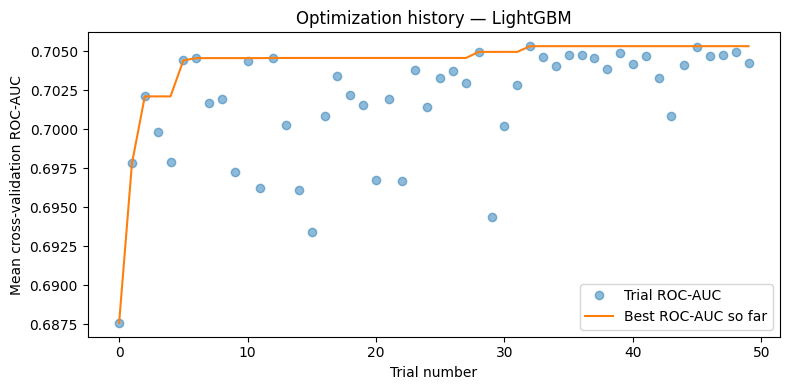

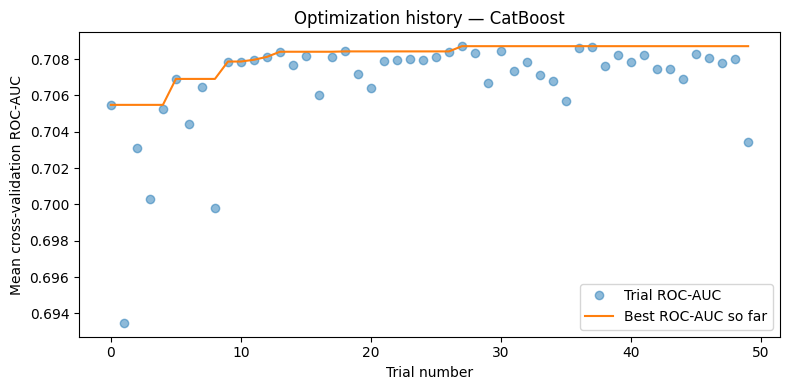

In [ ]:
for name, trials in [
    ("LightGBM", lightgbm_trials),
    ("CatBoost", catboost_trials)
]:
    plt.figure(figsize=(8, 4))

    plt.plot(
        trials["number"], trials["value"],
        "o", alpha=0.5, label="Trial ROC-AUC"
    )

    plt.plot(
        trials["number"], trials["value"].cummax(),
        label="Best ROC-AUC so far"
    )

    plt.xlabel("Trial number")
    plt.ylabel("Mean cross-validation ROC-AUC")
    plt.title(f"Optimization history — {name}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(tracking_dir / f"{name.lower()}_history.png", dpi=150)
    plt.show()

## 8. Explainability

##### We split the development data by patient into fitting and validation subsets. We fit the selected LightGBM pipeline on the fitting subset. The same fitted pipeline is used for explainability, calibration diagnostics and the fairness audit.

In [ ]:
fit_index, valid_index = next(
    cv.split(X_train, y_train, groups=groups_train)
)

X_fit = X_train.iloc[fit_index].copy()
X_valid = X_train.iloc[valid_index].copy()

y_fit = y_train.iloc[fit_index].copy()
y_valid = y_train.iloc[valid_index].copy()

In [ ]:
validation_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_columns),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant", fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_columns)
])

validation_pipeline = Pipeline([
    ("preprocessor", validation_preprocessor),
    ("model", LGBMClassifier(
        **study_lightgbm.best_params,
        random_state=42,
        verbosity=-1
    ))
])

validation_pipeline.fit(X_fit, y_fit)

y_proba_valid = validation_pipeline.predict_proba(X_valid)[:, 1]

In [ ]:
final_pipeline = validation_pipeline

#### We display the ten most important features based on their impact on LightGBM performance. Higher values indicate a greater contribution to reducing the training objective (log-loss) across the trees.

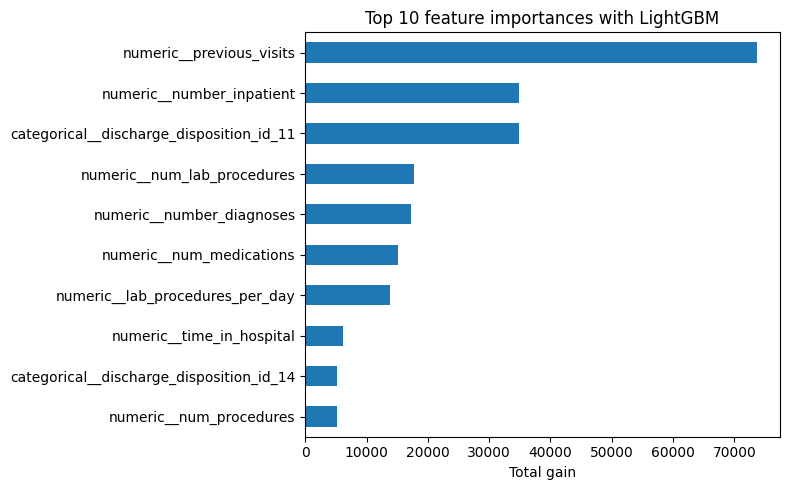

In [ ]:
model = final_pipeline.named_steps["model"]

feature_names = (
    final_pipeline.named_steps["preprocessor"].get_feature_names_out()
)

importance = pd.Series(
    model.booster_.feature_importance(importance_type="gain"),
    index=feature_names
)

importance.nlargest(10).sort_values().plot.barh(figsize=(8, 5))
plt.title("Top 10 feature importances with LightGBM")
plt.xlabel("Total gain")
plt.tight_layout()
plt.show()

##### We compute SHAP values for 300 stays using the fitted preprocessing. The summary plot shows how features influence the model's raw output (log-odds)

/Users/matisdouay/Desktop/Albert school/M2 - Albert School/Supervised Learning & Model Engineering/Supervised-learning-Diabetes/.venv/lib/python3.13/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


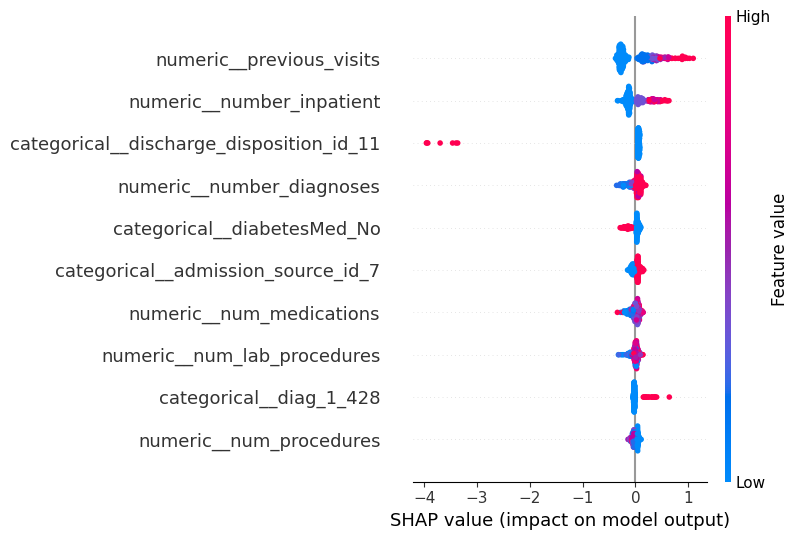

In [ ]:
import shap

X_shap = X_train.sample(300, random_state=42)

X_shap_transformed = (
    final_pipeline.named_steps["preprocessor"].transform(X_shap)
)

if hasattr(X_shap_transformed, "toarray"):
    X_shap_transformed = X_shap_transformed.toarray()

X_shap_transformed = pd.DataFrame(
    X_shap_transformed,
    columns=feature_names,
    index=X_shap.index
)

explainer = shap.TreeExplainer(model, model_output="raw")
shap_values = explainer.shap_values(X_shap_transformed)

shap.summary_plot(shap_values, X_shap_transformed, max_display=10)

##### We explain three stays from our fixed random sample. For each stay, we display the predicted readmission probability and the five largest absolute SHAP contributions. Positive contributions increase the raw prediction, while negative contributions decrease it. 
##### We verify that the baseline and all SHAP contributions reconstructs the model's raw score (log-odds).

In [ ]:
for i in [0, 1, 2]:
    print("Stay:", X_shap.index[i])
    print(
        "Predicted readmission probability:",
        final_pipeline.predict_proba(X_shap.iloc[[i]])[0, 1]
    )

    explanation = pd.DataFrame({
        "Feature": feature_names,
        "Value": X_shap_transformed.iloc[i].values,
        "SHAP": shap_values[i]
    })

    explanation["Absolute SHAP"] = explanation["SHAP"].abs()

    display(
        explanation.sort_values(
            "Absolute SHAP", ascending=False
        ).head(5)
    )

    reconstructed_score = explainer.expected_value + shap_values[i].sum()
    model_score = model.predict(
        X_shap_transformed.iloc[[i]], raw_score=True
    )[0]

    print("SHAP additivity check:", np.isclose(reconstructed_score, model_score))

Stay: 39397
Predicted readmission probability: 0.6057499973536408


,Feature,Value,SHAP,Absolute SHAP
6,numeric__number_inpatient,-0.503312,-0.213234,0.213234
397,categorical__diag_1_491,1.000000,0.176112,0.176112
69,categorical__admission_source_id_7,1.000000,0.161564,0.161564
8,numeric__previous_visits,-0.089435,0.122065,0.122065
3,numeric__num_medications,0.119619,0.076222,0.076222


SHAP additivity check: True
Stay: 66309
Predicted readmission probability: 0.23157992925718873


,Feature,Value,SHAP,Absolute SHAP
8,numeric__previous_visits,-0.523137,-0.300814,0.300814
6,numeric__number_inpatient,-0.503312,-0.160896,0.160896
0,numeric__time_in_hospital,-1.136935,-0.094118,0.094118
69,categorical__admission_source_id_7,1.000000,0.088594,0.088594
2,numeric__num_procedures,0.389052,-0.084272,0.084272


SHAP additivity check: True
Stay: 42168
Predicted readmission probability: 0.531330127341237


,Feature,Value,SHAP,Absolute SHAP
8,numeric__previous_visits,-0.523137,-0.224324,0.224324
1005,categorical__diag_2_428,1.000000,0.186930,0.186930
6,numeric__number_inpatient,-0.503312,-0.103045,0.103045
7,numeric__number_diagnoses,0.816531,0.102447,0.102447
2252,categorical__diabetesMed_No,0.000000,0.079945,0.079945


SHAP additivity check: True


In [ ]:
importance.nlargest(10)

numeric__previous_visits                    73760.727955
numeric__number_inpatient                   34915.453754
categorical__discharge_disposition_id_11    34889.524458
numeric__num_lab_procedures                 17668.919553
numeric__number_diagnoses                   17250.658038
numeric__num_medications                    15096.604290
numeric__lab_procedures_per_day             13848.581371
numeric__time_in_hospital                    6084.288099
categorical__discharge_disposition_id_14     5223.743895
numeric__num_procedures                      5187.702741
dtype: float64

## 9. Calibration diagnostics

##### We assess the fitted pipeline's predicted probabilities on the validation subset using a reliability diagram, the Brier score and ECE.

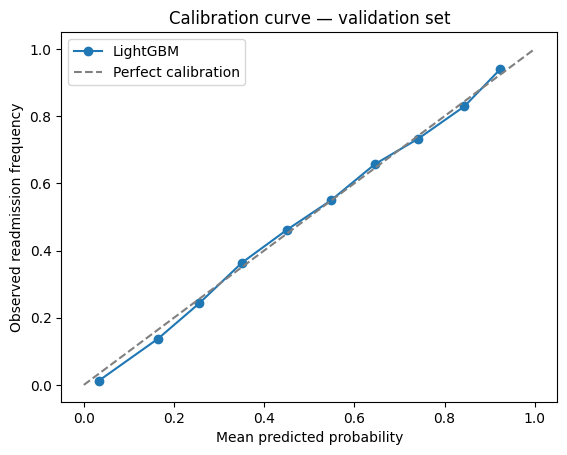

Brier score: 0.21552468552847948


In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

observed, predicted = calibration_curve(
    y_valid, y_proba_valid,
    n_bins=10,
    strategy="uniform"
)

plt.plot(predicted, observed, marker="o", label="LightGBM")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed readmission frequency")
plt.title("Calibration curve — validation set")
plt.legend()
plt.show()

print("Brier score:", brier_score_loss(y_valid, y_proba_valid))

In [ ]:
calibration = pd.DataFrame({
    "predicted": y_proba_valid,
    "observed": y_valid.to_numpy()
})

calibration["bin"] = pd.cut(
    calibration["predicted"],
    bins=np.linspace(0, 1, 11),
    include_lowest=True
)

grouped = calibration.groupby("bin", observed=True)

gaps = (grouped["predicted"].mean() - grouped["observed"].mean()).abs()
weights = grouped.size() / len(calibration)

ece = (gaps * weights).sum()

print("ECE:", ece)

ECE: 0.010763150222173357


We display the distribution of predicted probabilities using the same
ten equal-width intervals as the calibration curve. Bins containing
few stays may give less reliable estimates of observed readmission frequency.

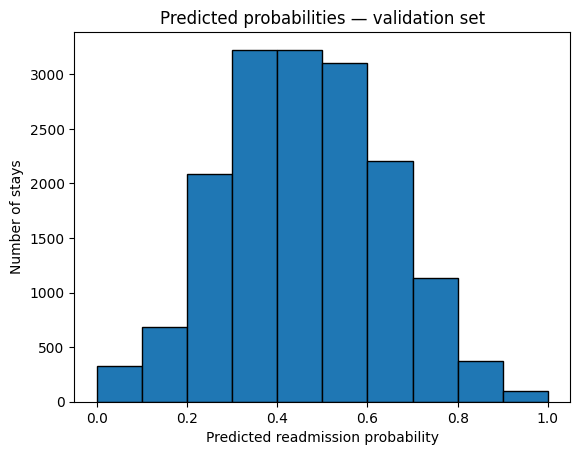

In [ ]:
plt.hist(
    y_proba_valid,
    bins=np.linspace(0, 1, 11),
    edgecolor="black"
)

plt.xlabel("Predicted readmission probability")
plt.ylabel("Number of stays")
plt.title("Predicted probabilities — validation set")
plt.show()

## 10. Fairness & bias audit

##### We audit performance across race groups, including an Unknown group. We choose equalized odds as our fairness definition, considering both true-positive and false-positive rates. We will prepare a group-specific threshold mitigation on development data and compare performance and fairness before and after on the held-out test set.

In [ ]:
sensitive_valid = X_valid["race"].astype("string").fillna("Unknown")

sensitive_valid.value_counts()

race
Caucasian          12325
AfricanAmerican     3071
Unknown              394
Hispanic             351
Other                231
Asian                 95
Name: count, dtype: Int64

##### We report validation-set performance by race group at a fixed threshold of 0.5. Equalized odds concerns differences in both true-positive and false-positive rates. Group sizes and error counts help interpret these differences, particularly for smaller groups.

In [ ]:
from sklearn.metrics import confusion_matrix

y_pred_valid = (y_proba_valid >= 0.5).astype(int)

audit = pd.DataFrame({
    "race": sensitive_valid.to_numpy(),
    "actual": y_valid.to_numpy(),
    "predicted": y_pred_valid
})

results = []

for group, data in audit.groupby("race"):
    tn, fp, fn, tp = confusion_matrix(
        data["actual"], data["predicted"], labels=[0, 1]
    ).ravel()

    results.append({
        "Group": group,
        "Stays": len(data),
        "Prevalence": data["actual"].mean(),
        "Selection rate": data["predicted"].mean(),
        "TPR": tp / (tp + fn) if tp + fn > 0 else np.nan,
        "FPR": fp / (fp + tn) if fp + tn > 0 else np.nan,
        "Precision": tp / (tp + fp) if tp + fp > 0 else np.nan,
        "False positives": fp,
        "False negatives": fn
    })

fairness_before = pd.DataFrame(results).set_index("Group")
fairness_before.round(3)

,Stays,Prevalence,Selection rate,TPR,FPR,Precision,False positives,False negatives
Group,,,,,,,,
AfricanAmerican,3071,0.451,0.398,0.554,0.270,0.628,455,618
Asian,95,0.274,0.168,0.269,0.130,0.438,9,19
Caucasian,12325,0.477,0.438,0.582,0.305,0.635,1967,2458
Hispanic,351,0.402,0.416,0.688,0.233,0.664,49,44
Other,231,0.377,0.316,0.529,0.188,0.630,27,41
Unknown,394,0.343,0.183,0.363,0.089,0.681,23,86


##### We measure the TPR and FPR gaps as the maximum minus minimum rate across race groups. The equalized odds gap is the larger of these two differences. Lower values indicate closer agreement between group rates, but must be interpreted alongside group sizes and uncertainty.

In [ ]:
fairness_gaps_before = (
    fairness_before[["TPR", "FPR"]].max()
    - fairness_before[["TPR", "FPR"]].min()
)

print(fairness_gaps_before)
print("Equalized odds gap:", fairness_gaps_before.max())

TPR    0.418712
FPR    0.216584
dtype: float64
Equalized odds gap: 0.4187124931805783


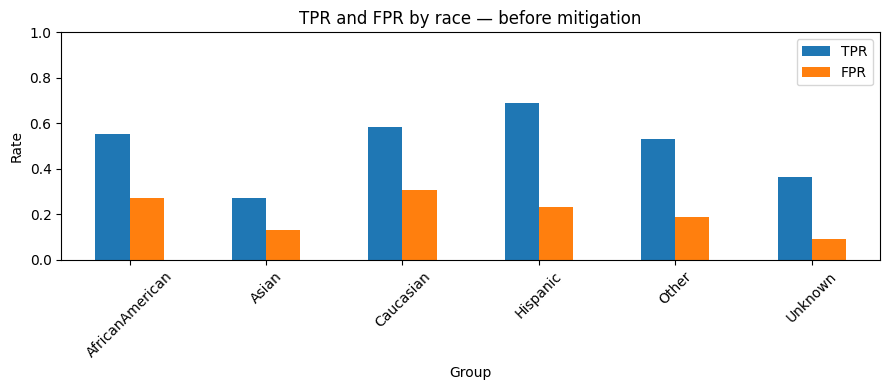

In [ ]:
fairness_before[["TPR", "FPR"]].plot.bar(figsize=(9, 4))
plt.ylabel("Rate")
plt.ylim(0, 1)
plt.title("TPR and FPR by race — before mitigation")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### We fit a ThresholdOptimizer on validation data to target equalized odds while maximizing accuracy. The underlying LightGBM pipeline remains fixed. The method learns group-specific decision rules using race.

In [ ]:
from fairlearn.postprocessing import ThresholdOptimizer

fair_model = ThresholdOptimizer(
    estimator=validation_pipeline,
    constraints="equalized_odds",
    objective="accuracy_score",
    predict_method="predict_proba",
    prefit=True
)

fair_model.fit(
    X_valid,
    y_valid,
    sensitive_features=sensitive_valid
)

ThresholdOptimizer(constraints='equalized_odds',
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('numeric',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['time_in_hospital',
                                                                                'num_lab_procedures',
                                                                                'num_procedures',
                                                                                'num_medications',
                                                                                'number_outpatient',
                                                                                'number_emergency',
                                                                                'number_inp...
                                                                                'acarbose',
                                                                                'miglitol',
                                                                                'troglitazone',
                                                                                'tolazamide',
                                                                                'examide',
                                                                                'citoglipton',
                                                                                'insulin',
                                                                                'glyburide.metformin',
                                                                                'glipizide.metformin',
                                                                                'glimepiride.pioglitazone', ...])])),
                                             ('model',
                                              LGBMClassifier(learning_rate=0.020617118634099374,
                                                             min_child_samples=100,
                                                             n_estimators=400,
                                                             num_leaves=71,
                                                             random_state=42,
                                                             verbosity=-1))]),
                   predict_method='predict_proba', prefit=True)

##### After freezing our modelling decisions, we compare the same LightGBM pipeline before and after threshold mitigation on the held-out test set. The baseline uses a threshold of 0.5; the mitigated predictions use the group-specific rules learned on validation data.

In [ ]:
sensitive_test = X_test["race"].astype("string").fillna("Unknown")

y_proba_test = validation_pipeline.predict_proba(X_test)[:, 1]
y_pred_before = (y_proba_test >= 0.5).astype(int)

y_pred_after = fair_model.predict(
    X_test,
    sensitive_features=sensitive_test,
    random_state=42
)

### Overall performance before and after mitigation

##### We compare test-set performance to assess the impact of fairness mitigation.

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score
)

performance = pd.DataFrame({
    "Before": [
        accuracy_score(y_test, y_pred_before),
        precision_score(y_test, y_pred_before, zero_division=0),
        recall_score(y_test, y_pred_before, zero_division=0),
        f1_score(y_test, y_pred_before, zero_division=0)
    ],
    "After": [
        accuracy_score(y_test, y_pred_after),
        precision_score(y_test, y_pred_after, zero_division=0),
        recall_score(y_test, y_pred_after, zero_division=0),
        f1_score(y_test, y_pred_after, zero_division=0)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1"]).T

display(performance.round(3))

print("Test ROC-AUC:", roc_auc_score(y_test, y_proba_test))

,Accuracy,Precision,Recall,F1
Before,0.648,0.623,0.569,0.595
After,0.642,0.607,0.599,0.603


Test ROC-AUC: 0.7069148710313543


### Test-set performance by race group

##### We report group sizes, prevalence, selection rates and error rates before and after mitigation. Results for smaller groups require caution.

In [ ]:
results = []

for version, predictions in [
    ("Before", y_pred_before),
    ("After", y_pred_after)
]:
    audit_test = pd.DataFrame({
        "race": sensitive_test.to_numpy(),
        "actual": y_test.to_numpy(),
        "predicted": predictions
    })

    for group, data in audit_test.groupby("race"):
        tn, fp, fn, tp = confusion_matrix(
            data["actual"], data["predicted"], labels=[0, 1]
        ).ravel()

        results.append({
            "Version": version,
            "Group": group,
            "Stays": len(data),
            "Prevalence": data["actual"].mean(),
            "Selection rate": data["predicted"].mean(),
            "TPR": tp / (tp + fn) if tp + fn > 0 else np.nan,
            "FPR": fp / (fp + tn) if fp + tn > 0 else np.nan,
            "Precision": tp / (tp + fp) if tp + fp > 0 else np.nan,
            "False positives": fp,
            "False negatives": fn
        })

fairness_test = pd.DataFrame(results)

fairness_test.set_index(["Version", "Group"]).round(3)

Stays  Prevalence  Selection rate    TPR    FPR  \
Version Group                                                              
Before  AfricanAmerican   3847       0.458           0.414  0.558  0.292   
        Asian              125       0.416           0.264  0.423  0.151   
        Caucasian        15089       0.460           0.426  0.579  0.296   
        Hispanic           393       0.394           0.361  0.542  0.244   
        Other              289       0.384           0.291  0.477  0.174   
        Unknown            410       0.283           0.173  0.371  0.095   
After   AfricanAmerican   3847       0.458           0.459  0.606  0.335   
        Asian              125       0.416           0.472  0.615  0.370   
        Caucasian        15089       0.460           0.447  0.601  0.316   
        Hispanic           393       0.394           0.407  0.542  0.319   
        Other              289       0.384           0.429  0.505  0.382   
        Unknown            410       0.283           0.412  0.578  0.347   

                         Precision  False positives  False negatives  
Version Group                                                         
Before  AfricanAmerican      0.618              609              778  
        Asian                0.667               11               30  
        Caucasian            0.625             2413             2925  
        Hispanic             0.592               58               71  
        Other                0.631               31               58  
        Unknown              0.606               28               73  
After   AfricanAmerican      0.604              699              695  
        Asian                0.542               27               20  
        Caucasian            0.619             2571             2772  
        Hispanic             0.525               76               71  
        Other                0.452               68               55  
        Unknown              0.396              102               49

### Fairness gaps before and after mitigation

##### We calculate the maximum minus minimum TPR and FPR across race groups. The equalized odds gap is the larger of these two differences. Lower values indicate smaller disparities in error rates.

In [ ]:
rates = fairness_test.groupby("Version")[["TPR", "FPR"]]

fairness_gaps = rates.max() - rates.min()

fairness_gaps["Equalized odds gap"] = fairness_gaps.max(axis=1)

fairness_gaps = fairness_gaps.reindex(["Before", "After"])

fairness_gaps.round(3)

,TPR,FPR,Equalized odds gap
Version,,,
Before,0.208,0.201,0.208
After,0.111,0.066,0.111


In [ ]:
fairness_dir = Path("results/fairness")
fairness_dir.mkdir(parents=True, exist_ok=True)

performance.to_csv(fairness_dir / "performance_before_after.csv")
fairness_test.to_csv(fairness_dir / "metrics_by_group.csv", index=False)
fairness_gaps.to_csv(fairness_dir / "fairness_gaps.csv")

### Fairness audit conclusion

The mitigation reduced the test-set equalized odds gap from 0.208 to 0.111.
The TPR gap decreased from 0.208 to 0.111, and the FPR gap from 0.201 to 0.066.
However, equalized odds was not fully achieved.

Recall increased from 0.569 to 0.599, while accuracy decreased from 0.648
to 0.642 and precision from 0.623 to 0.607. False-positive rates increased
in every group: smaller disparities therefore came with more false alarms.

After mitigation, the Other group had the lowest recall (0.505),
while the Unknown group had the lowest precision (0.396).
Estimates for smaller groups, including the Asian group with 125 test stays,
are less certain.

This mitigation requires race information at prediction time.
These results illustrate a trade-off between error-rate parity and
predictive performance, rather than proving that the model is fair.